## Análisis de los datos

In [8]:
import json
with open("Train/NER/data/train_gold.json", "r") as file:
    g = json.load(file)
with open("Train/NER/data/train_silver.json", "r") as file:
    t1 = json.load(file)
with open("Train/NER/data/train_silver_2025.json", "r") as file:
    t2 = json.load(file)

data = {**g, **t1, **t2}

In [9]:
entities = {}
total = 0
for pmid, doc in data.items():
    ents = doc["entities"]
    for ent in ents: 
        label = ent["label"]
        if label in set(entities.keys()): 
            entities[label] += 1
        else:
            entities[label] = 1
        total += 1

In [10]:
percentages = {k: round(100*v/total, 2)
    for k, v in entities.items()
}

In [11]:
print(percentages, entities)

{'dietary supplement': 3.65, 'chemical': 15.01, 'animal': 4.19, 'DDF': 33.9, 'anatomical location': 5.67, 'gene': 1.63, 'bacteria': 7.58, 'microbiome': 9.3, 'human': 8.05, 'biomedical technique': 5.5, 'statistical technique': 1.72, 'food': 1.37, 'drug': 2.43} {'dietary supplement': 2260, 'chemical': 9300, 'animal': 2595, 'DDF': 20997, 'anatomical location': 3510, 'gene': 1012, 'bacteria': 4695, 'microbiome': 5762, 'human': 4985, 'biomedical technique': 3405, 'statistical technique': 1063, 'food': 847, 'drug': 1508}


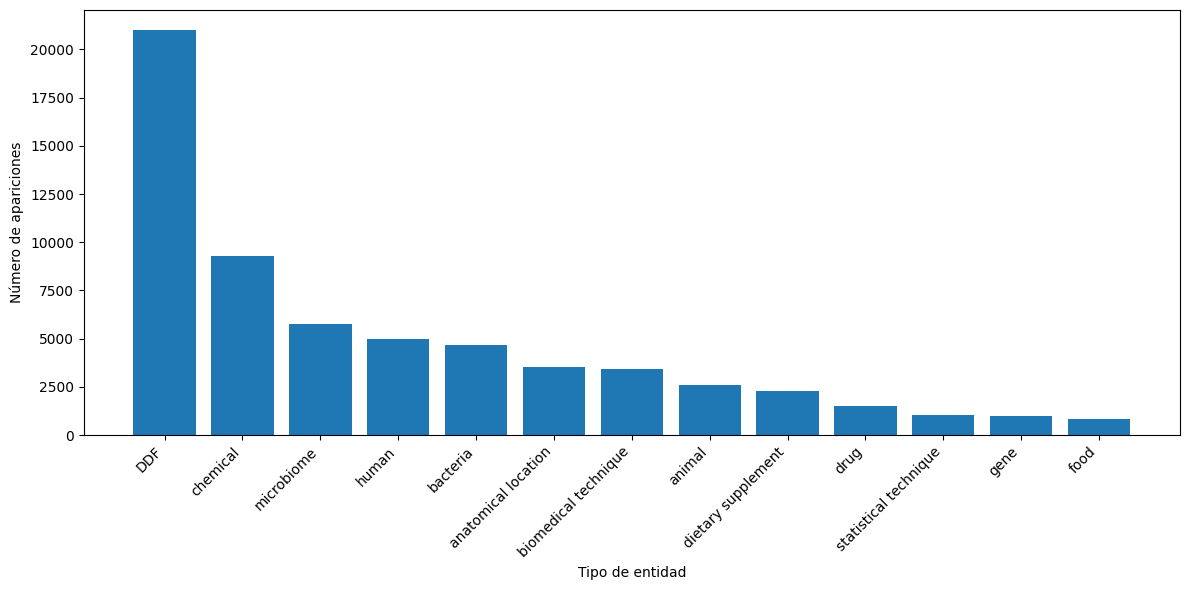

In [12]:
import matplotlib.pyplot as plt

entity_counts = {
    'dietary supplement': 2260,
    'chemical': 9300,
    'animal': 2595,
    'DDF': 20997,
    'anatomical location': 3510,
    'gene': 1012,
    'bacteria': 4695,
    'microbiome': 5762,
    'human': 4985,
    'biomedical technique': 3405,
    'statistical technique': 1063,
    'food': 847,
    'drug': 1508
}

# Ordenar


import matplotlib.pyplot as plt

labels, values = zip(
    *sorted(
        entity_counts.items(),
        key=lambda x: x[1],
        reverse=True
    )
)

plt.figure(figsize=(12, 6))

plt.bar(labels, values)


plt.xlabel("Tipo de entidad")
plt.ylabel("Número de apariciones")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("distribucion_entidades.png", dpi=300, bbox_inches="tight")
plt.show()


## Longitud en tokens de las entidades

In [25]:
# with open("Train/NER/data/train_data_full.json", "r") as file:
#     tokens = json.load(file)
print(processed[0])
longitud_total = []
labels = []
for chunk in processed: 
    for entity in chunk["ner"]: 
        i, f, l = entity
        long = f-i+1
        longitud_total.append((long))
longitud = {label.lower(): [] for label in entity_counts}
print(longitud)
labels = []
for chunk in processed: 
    for entity in chunk["ner"]: 
        i, f, l = entity
        long = f-i+1
        longitud[l].append(long)
print(longitud)

{'pmid': '38860943', 'tokenized_text': ['Probiotics', 'and', 'microbial', 'metabolites', 'maintain', 'barrier', 'and', 'neuromuscular', 'functions', 'and', 'clean', 'protein', 'aggregation', 'to', 'delay', 'disease', 'progression', 'in', 'TDP43', 'mutation', 'mice', '.', 'Amyotrophic', 'lateral', 'sclerosis', '(', 'ALS', ')', 'is', 'a', 'neuromuscular', 'disease', '.', 'The', 'ALS', 'mice', 'expressing', 'human', 'mutant', 'of', 'transactive', 'response', 'DNA', 'binding', 'protein', 'of', '43', 'kDa', '(', 'hmTDP43', ')', 'showed', 'intestinal', 'dysfunction', 'before', 'neuromuscular', 'symptoms', '.', 'We', 'hypothesize', 'that', 'restoring', 'the', 'intestinal', 'and', 'microbial', 'homeostasis', 'with', 'a', 'bacterial', 'metabolite', 'or', 'probiotics', 'delays', 'the', 'ALS', 'disease', 'onset', '.', 'We', 'investigate', 'the', 'pathophysiological', 'changes', 'in', 'the', 'intestine', 'and', 'neurons', ',', 'intestinal', 'and', 'blood', '-', 'brain', 'barriers', ',', 'and', 'in

In [22]:
import pandas as pd
for k, v in longitud.items():
    print("Metricas de ", k)
    s = pd.Series(v)
    max_span = 12
    covered = sum(l <= max_span for l in v)
    coverage = covered / len(v) * 100
    print(f"{coverage:.2f}%")
    print(s.describe())

Metricas de  dietary supplement
99.42%
count    2260.000000
mean        1.907522
std         1.871204
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        25.000000
dtype: float64
Metricas de  chemical
99.15%
count    9300.000000
mean        2.457849
std         2.341490
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        33.000000
dtype: float64
Metricas de  animal
97.88%
count    2595.000000
mean        3.277071
std         3.194165
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max        31.000000
dtype: float64
Metricas de  ddf
99.85%
count    20997.000000
mean         2.197695
std          1.584785
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         33.000000
dtype: float64
Metricas de  anatomical location
99.60%
count    3510.000000
mean        1.801709
std         1.647471
min         1.000000
25%         1.000

/tmp/ipykernel_171986/1366745619.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(datos, labels=labels, showmeans=True)


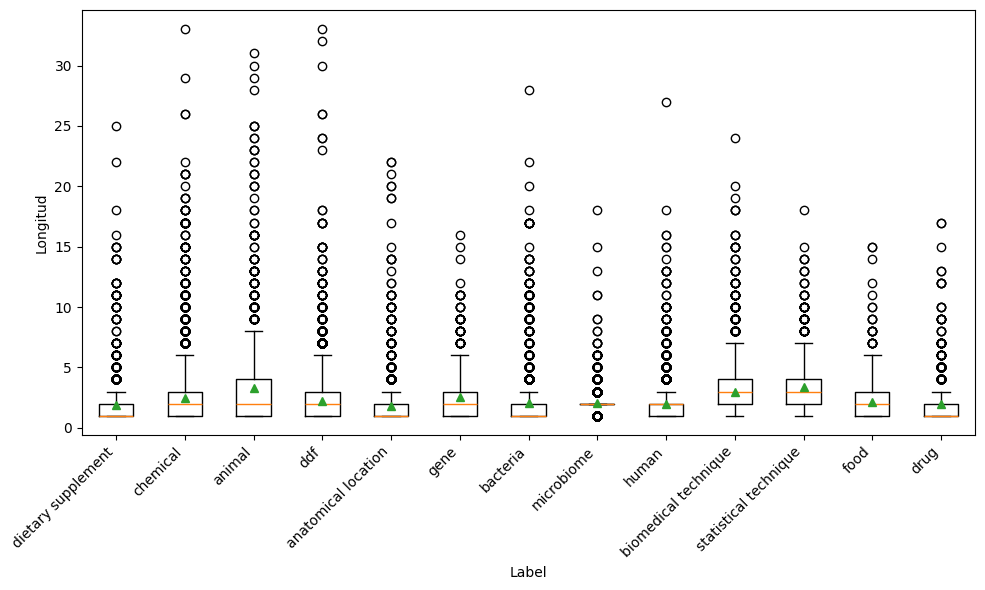

In [19]:
import matplotlib.pyplot as plt
def boxplot_longitudes_por_label(longitudes_por_label):
    # Quitamos labels sin valores, por si acaso
    datos_filtrados = {
        label: longitudes
        for label, longitudes in longitudes_por_label.items()
        if len(longitudes) > 0
    }

    labels = list(datos_filtrados.keys())
    datos = list(datos_filtrados.values())

    plt.figure(figsize=(10, 6))
    plt.boxplot(datos, labels=labels, showmeans=True)

    plt.xlabel("Label")
    plt.ylabel("Longitud")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
boxplot_longitudes_por_label(longitud)

In [13]:
import re
def tokenize_text_with_positions(text):
    # Split text into tokens, preserving punctuation (except for hyphens and underscores)
    tokens = []
    token_spans = []  # list of (start_char_index, end_char_index) for each token
    pattern = re.compile(r"\w+|[.,!?;:\'\"()\[\]{}<>]|[\s]+|\S")
    for match in pattern.finditer(text):
        token = match.group()
        if token.isspace():
            continue  # Skip whitespace tokens
        start_pos = match.start()
        if re.match(r"\w+-\w+", token) or re.match(r"\w+_\w+", token):
            # Keep hyphenated or underscored words intact
            tokens.append(token)
            token_spans.append((start_pos, match.end()))
        else:
            # Split contractions (e.g., "don't" -> "don", "'", "t")
            contraction_match = re.match(r"(\w+)(')(\w+)", token)
            if contraction_match:
                groups = contraction_match.groups()
                for group in groups:
                    end_pos = start_pos + len(group)
                    tokens.append(group)
                    token_spans.append((start_pos, end_pos))
                    start_pos = end_pos
            else:
                tokens.append(token)
                token_spans.append((start_pos, match.end()))
    return tokens, token_spans

def process_annotations(data):
    output_data = []

    for doc_id, doc_data in data.items():
        overall_tokenized_text = []
        overall_ner = []
        overall_spans = []
        token_offset = 0

        fields = ["title", "abstract"]

        for field in fields:
            text = doc_data["metadata"].get(field, "")
            tokens, token_spans = tokenize_text_with_positions(text)

            # Collect entities for this field
            field_entities = []
            for entity in doc_data.get("entities", []):
                mention_location = entity.get("location", "")
                if mention_location == field:
                    field_entities.append(entity)

            # Map entities from character indices to token indices
            for entity in field_entities:
                entity_start_char = entity["start_idx"]
                entity_end_char = entity["end_idx"] + 1  # Adjusting end index to be exclusive
                entity_label = entity["label"]

                entity_start_token_index = None
                entity_end_token_index = None

                for i, (token_start_char, token_end_char) in enumerate(token_spans):
                    if token_end_char <= entity_start_char:
                        continue  # Token is before the entity
                    if token_start_char >= entity_end_char:
                        break  # Token is after the entity
                    # Token overlaps with entity
                    if entity_start_token_index is None:
                        entity_start_token_index = i
                    entity_end_token_index = i  # Update to the last overlapping token

                if entity_start_token_index is not None and entity_end_token_index is not None:
                    overall_ner.append([
                        entity_start_token_index + token_offset,
                        entity_end_token_index + token_offset,
                        entity_label.lower()
                    ])
                else:
                    print(f"Warning: Could not find tokens for entity in doc {doc_id}, field {field}")

            # Append tokens to the overall tokenized text
            overall_tokenized_text.extend(tokens)
            overall_spans.extend(token_spans)
            token_offset += len(tokens)

        # Sort the word positions by the start index
        overall_ner.sort(key=lambda x: x[0])

        # Create the output dictionary for this document
        output_doc = {
            "pmid": doc_id,
            "tokenized_text": overall_tokenized_text,
            "ner": overall_ner,
            "token_indexes": overall_spans
        }

        output_data.append(output_doc)

    return output_data

In [14]:
longitud

{'dietary supplement': [(0, 0, 1),
  (72, 72, 1),
  (302, 305, 4),
  (327, 327, 1),
  (365, 365, 1),
  (401, 401, 1),
  (323, 323, 1),
  (102, 107, 6),
  (279, 281, 3),
  (6, 7, 2),
  (16, 17, 2),
  (48, 49, 2),
  (64, 65, 2),
  (103, 104, 2),
  (110, 110, 1),
  (116, 117, 2),
  (125, 125, 1),
  (488, 488, 1),
  (494, 494, 1),
  (508, 508, 1),
  (258, 258, 1),
  (0, 4, 5),
  (233, 234, 2),
  (296, 296, 1),
  (335, 336, 2),
  (383, 384, 2),
  (129, 134, 6),
  (215, 215, 1),
  (240, 241, 2),
  (248, 251, 4),
  (295, 298, 4),
  (300, 303, 4),
  (334, 336, 3),
  (338, 340, 3),
  (374, 374, 1),
  (5, 6, 2),
  (49, 50, 2),
  (79, 80, 2),
  (137, 138, 2),
  (178, 181, 4),
  (187, 188, 2),
  (218, 219, 2),
  (286, 286, 1),
  (2, 5, 4),
  (92, 95, 4),
  (170, 172, 3),
  (269, 271, 3),
  (128, 130, 3),
  (153, 154, 2),
  (205, 206, 2),
  (8, 9, 2),
  (11, 11, 1),
  (42, 42, 1),
  (44, 44, 1),
  (74, 75, 2),
  (114, 115, 2),
  (135, 136, 2),
  (146, 147, 2),
  (162, 163, 2),
  (404, 404, 1),
  (4

In [14]:
processed = process_annotations(data)

In [26]:
longitud_total

[]

In [29]:
import pandas as pd

s = pd.Series(longitud_total)
num_mayores_10 = (s > 12).sum()
pct_mayores_10 = 100 * num_mayores_10 / len(s)

print(f"Cantidad: {num_mayores_10}")
print(f"Porcentaje: {pct_mayores_10:.2f}%")
print(s.describe())
print("\nEstadísticas adicionales:")
print(f"> 12 tokens: {(s > 12).sum()}")
print(f"> 20 tokens: {(s > 20).sum()}")
print(f"> 30 tokens: {(s > 30).sum()}")
print(f"Máximo: {s.max()}")
print(len(longitud_total))

Cantidad: 273
Porcentaje: 0.44%
count    61939.000000
mean         2.266407
std          1.904002
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         33.000000
dtype: float64

Estadísticas adicionales:
> 12 tokens: 273
> 20 tokens: 43
> 30 tokens: 4
Máximo: 33
61939


In [52]:
import numpy as np
x = longitud
print(f"Número de muestras: {len(x)}")
print(f"Media: {np.mean(x):.3f}")
print(f"Mediana: {np.median(x):.3f}")
print(f"Desviación estándar: {np.std(x):.3f}")
print(f"Varianza: {np.var(x):.3f}")
print(f"Mínimo: {np.min(x)}")
print(f"Máximo: {np.max(x)}")
print(f"Rango: {np.max(x)-np.min(x)}")
print(f"Percentil 25: {np.percentile(x, 25):.3f}")
print(f"Percentil 75: {np.percentile(x, 75):.3f}")
print(f"Percentil 75: {np.percentile(x, 95):.3f}")
print(f"IQR: {np.percentile(x,75)-np.percentile(x,25):.3f}")

Número de muestras: 61939
Media: 2.266
Mediana: 2.000
Desviación estándar: 1.904
Varianza: 3.625
Mínimo: 1
Máximo: 33
Rango: 32
Percentil 25: 1.000
Percentil 75: 3.000
Percentil 75: 5.000
IQR: 2.000


In [18]:
longitud

{'dietary supplement': [1,
  1,
  4,
  1,
  1,
  1,
  1,
  6,
  3,
  2,
  2,
  2,
  2,
  2,
  1,
  2,
  1,
  1,
  1,
  1,
  1,
  5,
  2,
  1,
  2,
  2,
  6,
  1,
  2,
  4,
  4,
  4,
  3,
  3,
  1,
  2,
  2,
  2,
  2,
  4,
  2,
  2,
  1,
  4,
  4,
  3,
  3,
  3,
  2,
  2,
  2,
  1,
  1,
  1,
  2,
  2,
  2,
  2,
  2,
  1,
  1,
  2,
  3,
  1,
  4,
  1,
  3,
  4,
  5,
  3,
  1,
  1,
  1,
  1,
  4,
  2,
  2,
  3,
  2,
  3,
  2,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  2,
  2,
  1,
  1,
  2,
  2,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  2,
  4,
  1,
  1,
  1,
  1,
  1,
  1,
  5,
  5,
  5,
  5,
  5,
  5,
  5,
  5,
  5,
  4,
  1,
  4,
  3,
  1,
  3,
  1,
  1,
  1,
  1,
  1,
  4,
  1,
  1,
  1,
  1,
  4,
  3,
  2,
  2,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  8,
  3,
  3,
  3,
  3,
  3,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  4,
  1,
  4,
  3,
  4,
  4,
  2,
  2,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  6,
  1,
  1,
  1,
  2,
  2,
  2,
  1,
  3

## Longitud de los textos

In [81]:
num_entidades

[79,
 63,
 40,
 16,
 55,
 51,
 26,
 37,
 56,
 41,
 42,
 49,
 30,
 23,
 67,
 50,
 54,
 35,
 42,
 35,
 54,
 62,
 30,
 49,
 25,
 44,
 25,
 41,
 34,
 58,
 27,
 21,
 70,
 28,
 43,
 22,
 44,
 34,
 35,
 47,
 47,
 34,
 31,
 55,
 42,
 22,
 42,
 25,
 33,
 49,
 35,
 28,
 36,
 28,
 50,
 22,
 28,
 25,
 58,
 29,
 67,
 34,
 70,
 42,
 39,
 55,
 47,
 75,
 46,
 14,
 49,
 39,
 54,
 45,
 26,
 76,
 46,
 25,
 46,
 54,
 13,
 45,
 27,
 47,
 43,
 39,
 38,
 21,
 18,
 30,
 42,
 18,
 26,
 25,
 33,
 49,
 49,
 22,
 27,
 48,
 30,
 18,
 25,
 35,
 43,
 55,
 44,
 62,
 34,
 29,
 42,
 16,
 50,
 50,
 83,
 50,
 58,
 14,
 43,
 41,
 19,
 49,
 47,
 39,
 28,
 38,
 42,
 77,
 13,
 48,
 55,
 47,
 37,
 35,
 45,
 31,
 38,
 47,
 65,
 34,
 64,
 26,
 31,
 20,
 33,
 15,
 35,
 39,
 55,
 31,
 43,
 27,
 50,
 46,
 24,
 21,
 44,
 37,
 38,
 31,
 46,
 27,
 28,
 41,
 26,
 31,
 19,
 33,
 12,
 34,
 28,
 33,
 24,
 28,
 22,
 19,
 43,
 49,
 31,
 14,
 22,
 46,
 47,
 30,
 52,
 36,
 34,
 33,
 29,
 30,
 32,
 34,
 31,
 36,
 44,
 43,
 39,
 57,
 22,
 50,


In [130]:
long_textos = list(len(processed[i]["tokenized_text"]) for i in range(len(processed)))
maximo = max(long_textos)
idx_max = long_textos.index(maximo)
long_textos.pop(idx_max)
num_entidades = list(len(processed[i]["ner"]) for i in range(len(processed)))
num_entidades.pop(idx_max)


32

0        1
1        1
2        4
3        1
4        1
        ..
61934    2
61935    1
61936    1
61937    1
61938    2
Length: 61939, dtype: int64


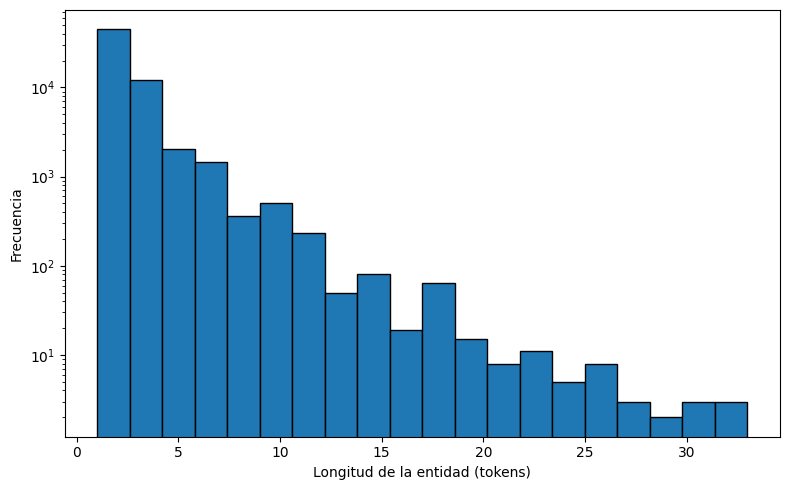

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

lengths = [
    length
    for category_lengths in longitud.values()
    for length in category_lengths
]
s = pd.Series(lengths)
print(s)
plt.figure(figsize=(8,5))

s.plot.hist(
    bins=20,
    edgecolor="black"
)

plt.yscale("log")
plt.xlabel("Longitud de la entidad (tokens)")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.savefig("longitud_entidades.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
import numpy as np

# X: Mediana de la longitud de las entidades
X = np.median(lengths)

# Y: Percentil 95 de la longitud
Y = np.percentile(lengths, 95)

# Z: Porcentaje de entidades con más de 4 tokens
Z = np.mean(np.array(lengths) > 4) * 100

print(f"Mediana: {X:g} tokens")
print(f"Percentil 95: {Y:.2f} tokens")
print(f"Entidades con más de 4 tokens: {Z:.2f}%")

Mediana: 2 tokens
Percentil 95: 5.00 tokens
Entidades con más de 4 tokens: 7.88%


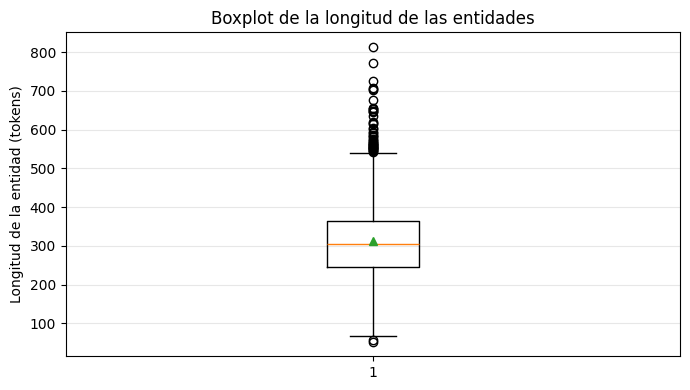

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.boxplot(
    long_textos,
    vert=True,
    showmeans=True
)

plt.ylabel("Longitud de la entidad (tokens)")
plt.title("Boxplot de la longitud de las entidades")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

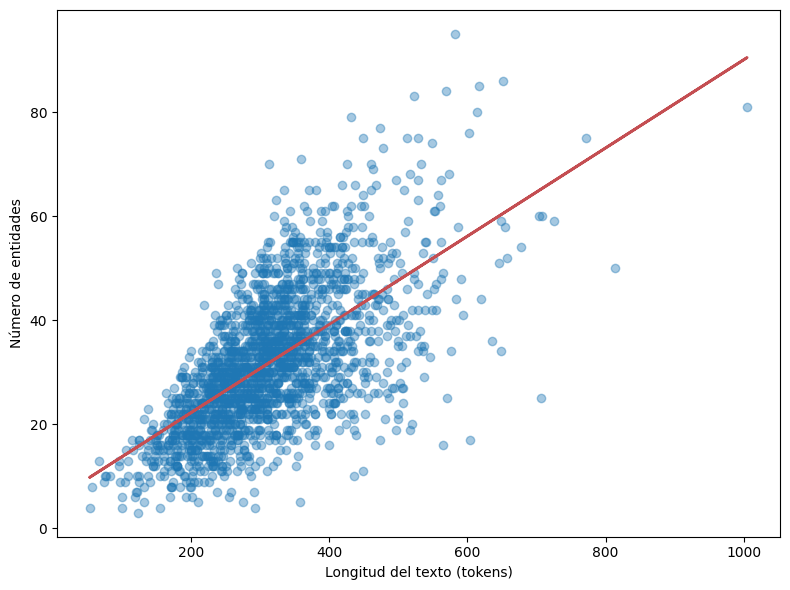

Correlación de Pearson: 0.640


In [156]:
    import numpy as np
    import matplotlib.pyplot as plt
    
    x = np.array(long_textos)
    y = np.array(num_entidades)
    
    plt.figure(figsize=(8,6))
    
    plt.scatter(
        x,
        y,
        alpha=0.4
    )
    
    m, b = np.polyfit(x, y, 1)
    
    plt.plot(
        x,
        m*x + b,
        linewidth=2,
        color = "#C44E52"
    )
    
    plt.xlabel("Longitud del texto (tokens)")
    plt.ylabel("Número de entidades")
    
    plt.tight_layout()
    
    plt.savefig("scatter_long-ents.png", dpi=300, bbox_inches="tight")
    plt.show()
    
    import pandas as pd
    
    corr = pd.Series(long_textos).corr(
        pd.Series(num_entidades),
        method="pearson"
    )
    
    print(f"Correlación de Pearson: {corr:.3f}")

# Análsis de Relaciones

In [28]:
import json
import numpy as np
import matplotlib.pyplot as plt
with open("Train/RE/data/train_annotated.json", "r") as file:
    dataset = json.load(file)
distancias = []

for doc in dataset:

    vertexSet = doc["vertexSet"]

    for rel in doc.get("labels", []):

        h_idx = rel["h"]
        t_idx = rel["t"]

        h_ent = vertexSet[h_idx][0]
        t_ent = vertexSet[t_idx][0]

        h_start, h_end = h_ent["pos"]
        t_start, t_end = t_ent["pos"]

        distancia = max(
            0,
            max(h_start, t_start)
            - min(h_end, t_end)
        )

        distancias.append(distancia)

print(f"Número de relaciones: {len(distancias)}")
print(f"Media: {np.mean(distancias):.2f}")
print(f"Mediana: {np.median(distancias):.2f}")
print(f"Máximo: {np.max(distancias)}")

Número de relaciones: 30073
Media: 11.30
Mediana: 7.00
Máximo: 239


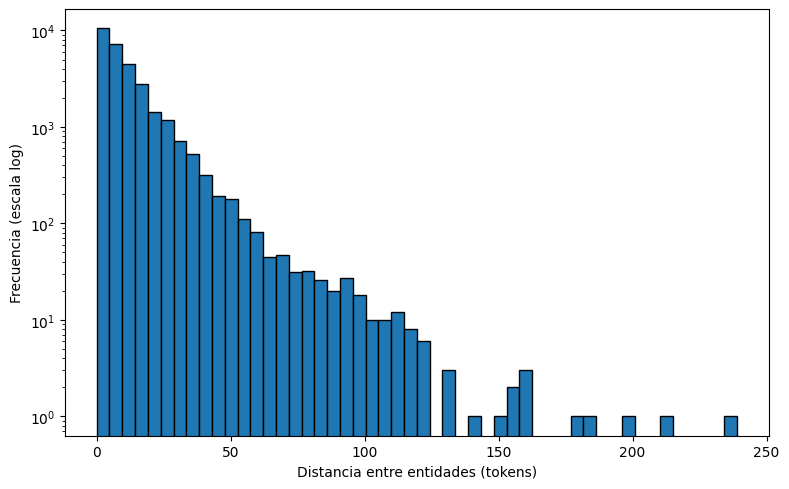

In [29]:
plt.figure(figsize=(8,5))

plt.hist(
    distancias,
    bins=50,
    edgecolor="black"
)

plt.yscale("log")

plt.xlabel("Distancia entre entidades (tokens)")
plt.ylabel("Frecuencia (escala log)")


plt.tight_layout()
plt.savefig('distancia_relaciones.png', dpi=300, bbox_inches="tight")
plt.show()

In [31]:
rels = {}
for doc in dataset:
    relations = doc["labels"]
    for relation in doc["labels"] :
        label = relation["r"].title()
        if label not in rels:
            rels[label] = 1
        else: rels[label] += 1

In [32]:
rels

{'Is A': 1038,
 'Target': 3970,
 'Located In': 3974,
 'Administered': 590,
 'Interact': 1514,
 'Change Expression': 242,
 'Impact': 1868,
 'Part Of': 1002,
 'Is Linked To': 3501,
 'Change Abundance': 1069,
 'Affect': 2113,
 'Influence': 6115,
 'Produced By': 328,
 'Strike': 599,
 'Change Effect': 832,
 'Used By': 1297,
 'Compared To': 21}

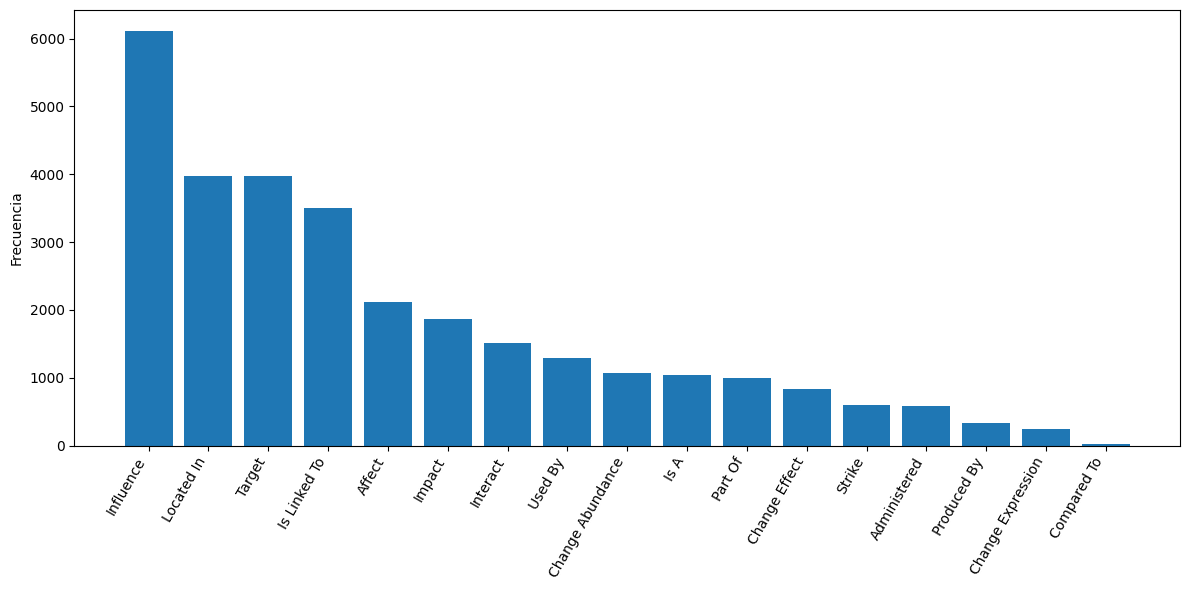

In [33]:

items = sorted(rels.items(), key=lambda x: x[1], reverse=True)

labels = [x[0] for x in items]
values = [x[1] for x in items]

plt.figure(figsize=(12, 6))
plt.bar(labels, values)

plt.xticks(rotation=60, ha='right')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.savefig('distribucion_relaciones.png', dpi=300, bbox_inches="tight")
plt.show()